In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.tree import DecisionTreeClassifier, plot_tree


In [32]:
# load dataset
df = pd.read_excel("Online Retail.xlsx")

# Display first five records
df.head()

# Dataset info
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB
None


In [30]:
df = df.dropna(subset=["CustomerID"])

df = df[~df["InvoiceNo"].astype(str).str.startswith("C")]

df = df[df["Quantity"]>0]
df = df[df["UnitPrice"]>0]

df["TotalAmount"] = df["Quantity"] * df["UnitPrice"]

print(df.shape)
df.head()

(397884, 9)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalAmount
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [31]:
customer_data = df.groupby("CustomerID").agg(
    TotalSpend = ("TotalAmount", "sum"),
    TotalQuantity = ("Quantity", "sum"),
    NumberOfTransactions = ("InvoiceNo", "nunique"),
    NumberOfProducts = ("StockCode", "nunique"),
    AverageOrderValue = ("TotalAmount", "mean"),
    Country = ("Country", "first")
).reset_index()

customer_data.head()

,CustomerID,TotalSpend,TotalQuantity,NumberOfTransactions,NumberOfProducts,AverageOrderValue,Country
0,12346.0,77183.60,74215,1,1,77183.600000,United Kingdom
1,12347.0,4310.00,2458,7,103,23.681319,Iceland
2,12348.0,1797.24,2341,4,22,57.975484,Finland
3,12349.0,1757.55,631,1,73,24.076027,Italy
4,12350.0,334.40,197,1,17,19.670588,Norway


In [34]:
customer_data["Segment"] = pd.qcut(
    customer_data["TotalSpend"], 
    q=3,
    labels = ["Low Value", "Medium Value", "High Value"]
)
print(customer_data["Segment"].value_counts())

Segment
Low Value       1446
Medium Value    1446
High Value      1446
Name: count, dtype: int64


In [37]:
features = [
    "TotalQuantity",
    "NumberOfTransactions",
    "NumberOfProducts",
    "AverageOrderValue",
]

X = customer_data[features]
y = customer_data["Segment"]

In [38]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size = 0.20,
    random_state = 42,
    stratify = y
)

In [41]:
id3_model = DecisionTreeClassifier(
    criterion = "entropy",
    random_state = 42,
    max_depth = 4
)
id3_model.fit(X_train, y_train)
y_pred = id3_model.predict(X_test)

print("Predictions:")
print(y_pred[:20])

Predictions:
['Low Value' 'Low Value' 'Low Value' 'Low Value' 'Medium Value'
 'Low Value' 'Low Value' 'High Value' 'Low Value' 'Medium Value'
 'Low Value' 'Medium Value' 'High Value' 'High Value' 'High Value'
 'High Value' 'Low Value' 'Low Value' 'High Value' 'Low Value']


In [43]:
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy", accuracy)
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy 0.8467741935483871

Classification Report:
              precision    recall  f1-score   support

  High Value       0.93      0.87      0.90       289
   Low Value       0.87      0.85      0.86       289
Medium Value       0.75      0.82      0.78       290

    accuracy                           0.85       868
   macro avg       0.85      0.85      0.85       868
weighted avg       0.85      0.85      0.85       868



In [45]:
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))


Confusion Matrix:
[[251   2  36]
 [  0 247  42]
 [ 19  34 237]]


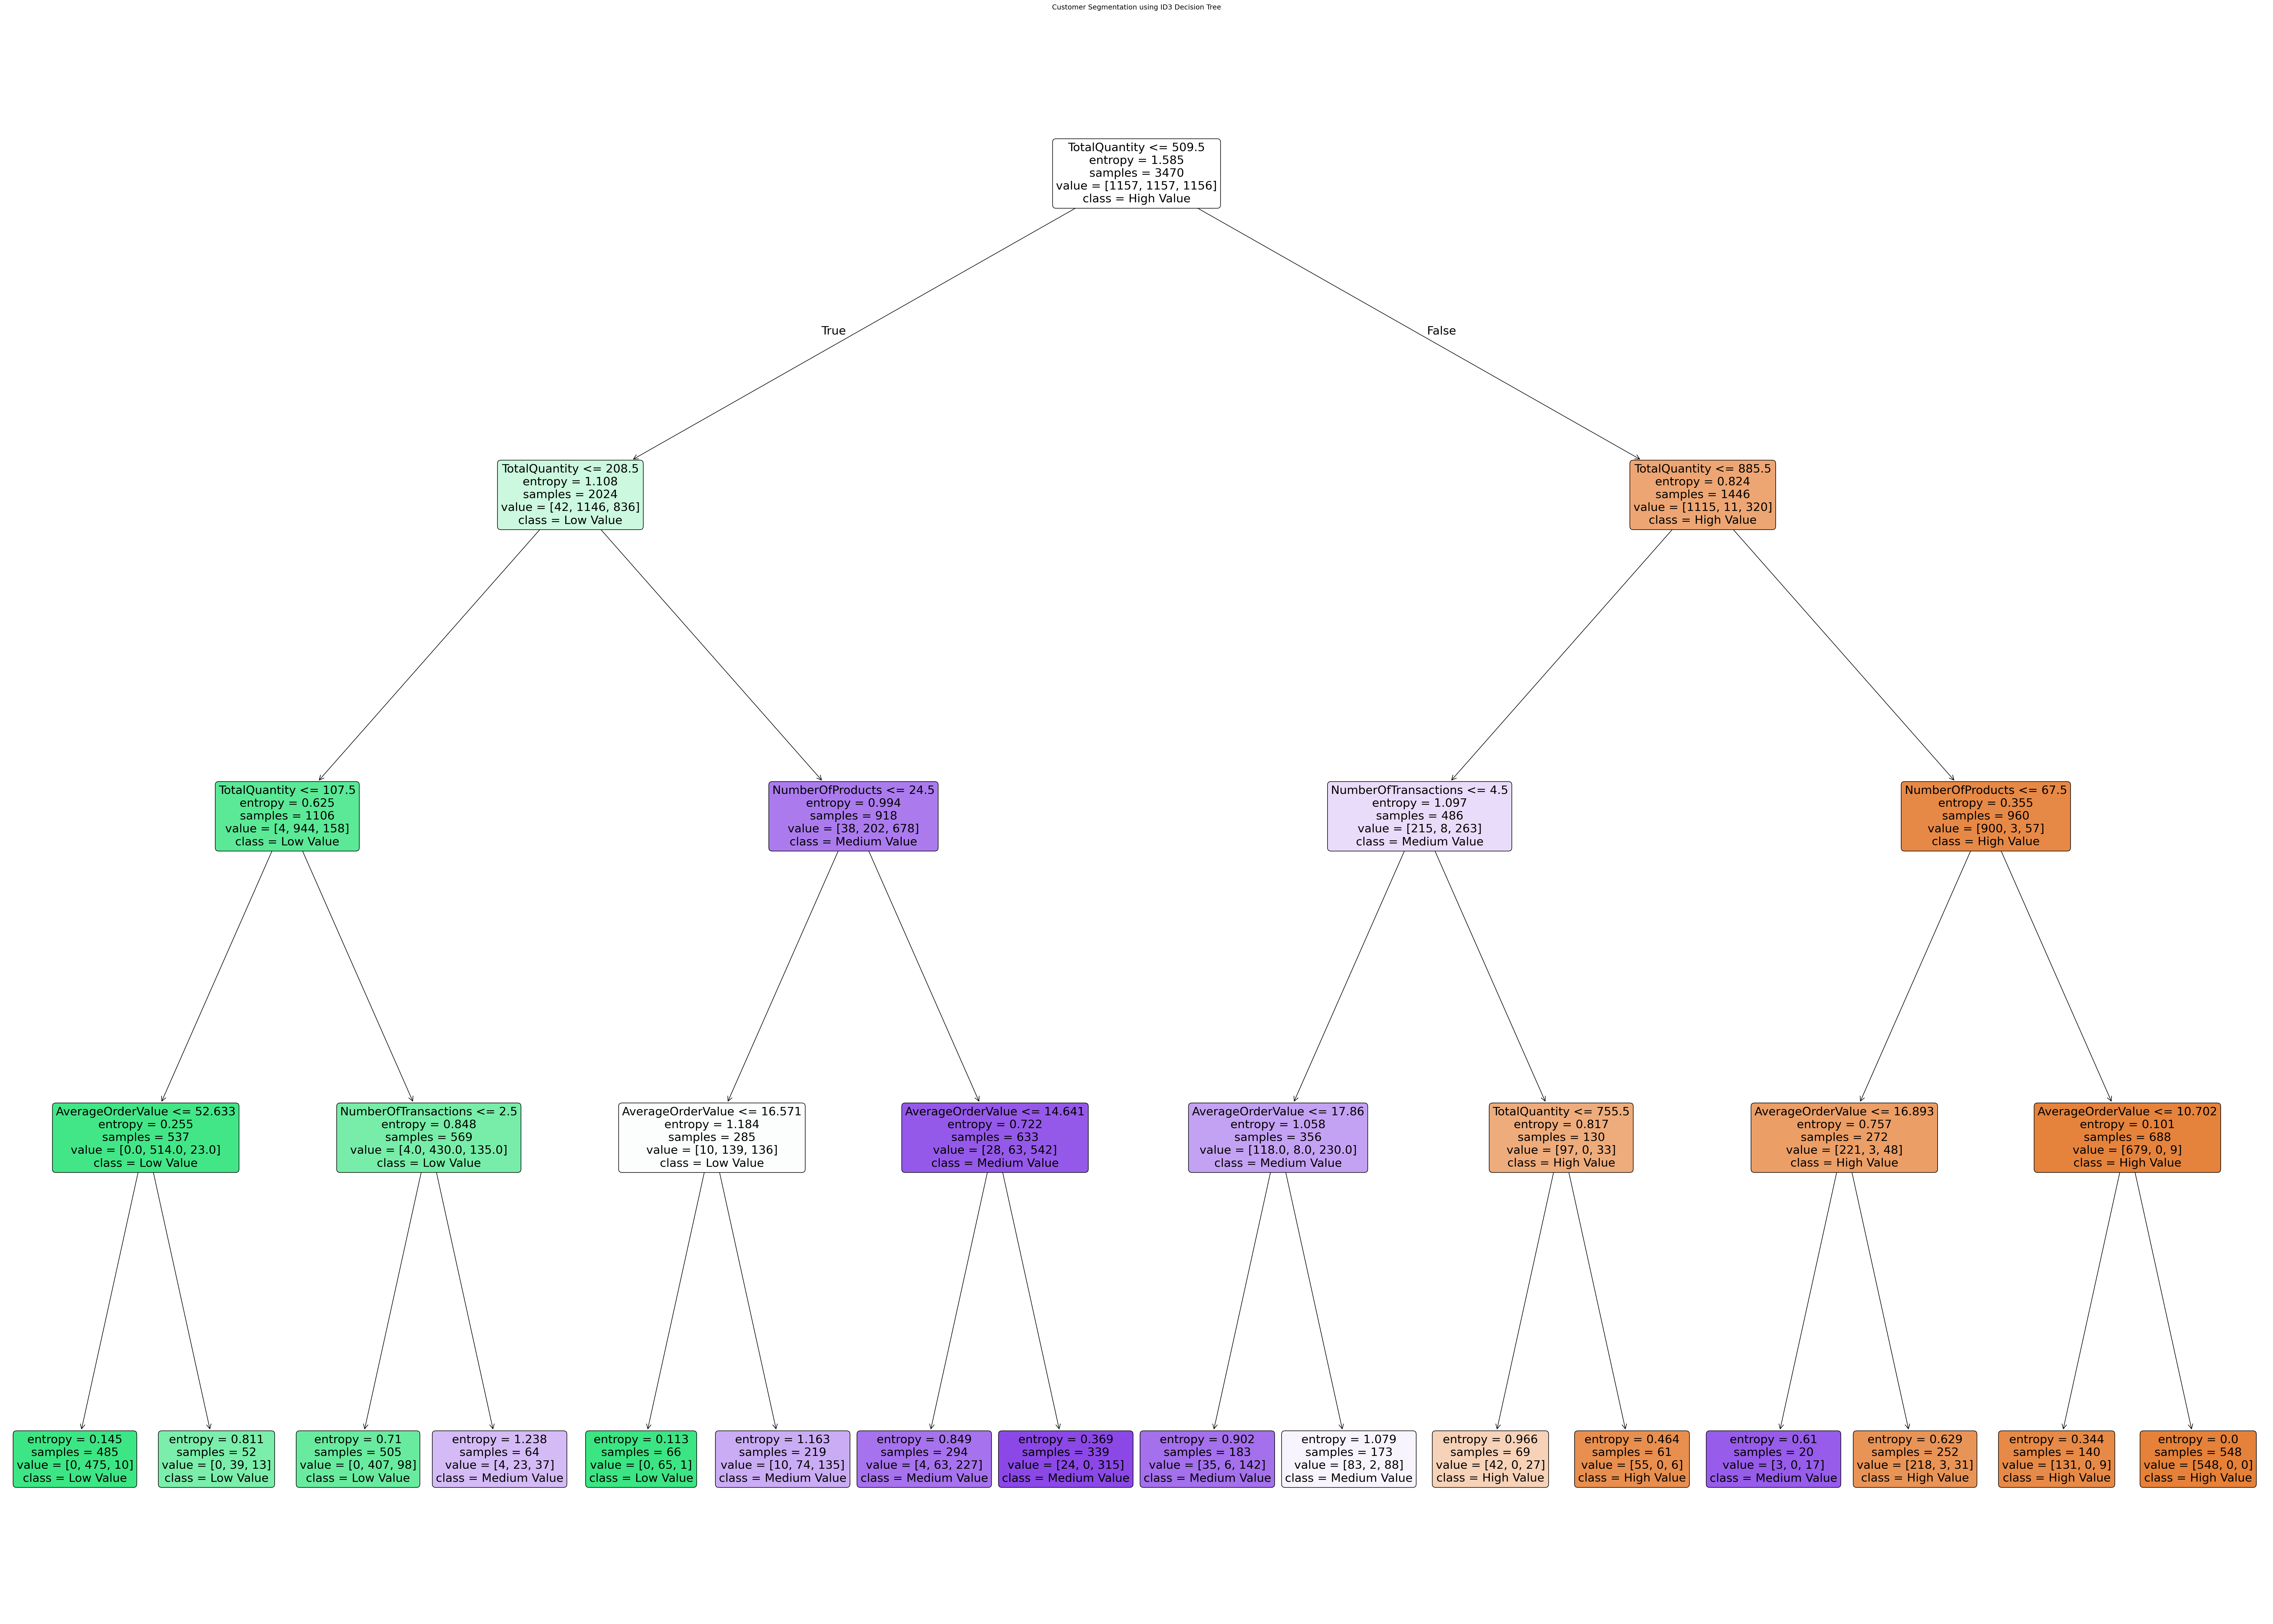

In [73]:
importance = pd.DataFrame({
    "Feature": features,
    "Importance": id3_model.feature_importances_
})

importance_sorted = importance.sort_values(
    "Importance",
    ascending = True
)

plt.figure(figsize=(70, 50), dpi=150)

plot_tree(
    id3_model,
    feature_names = features,
    class_names = id3_model.classes_,
    filled = True,
    rounded = True,
    proportion = False,
    fontsize = 20
)
plt.title("Customer Segmentation using ID3 Decision Tree")
plt.show()

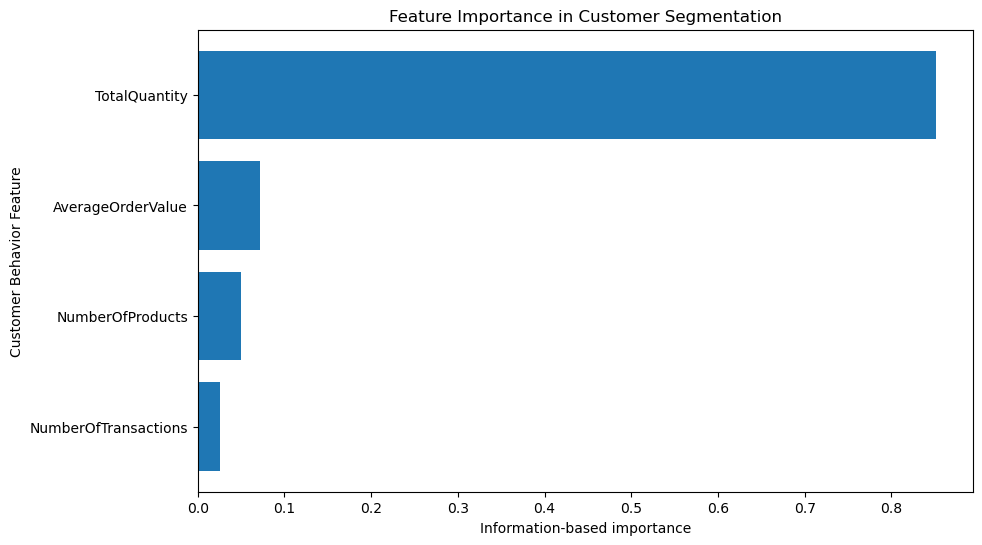

In [54]:
plt.figure(figsize=(10,6))
importance_sorted = importance.sort_values(
    "Importance",
    ascending = True
)
plt.barh(
    importance_sorted["Feature"],
    importance_sorted["Importance"]
)

plt.xlabel("Information-based importance")
plt.ylabel("Customer Behavior Feature")
plt.title("Feature Importance in Customer Segmentation")
plt.show()